# Heart murmur detection from phonocardiograms (CirCor DigiScope)

**Machine Learning II (CC3043), FCUP, 2026/2027 — group project**

For each **patient** we predict whether a heart murmur is *Present*, *Absent* or *Unknown* from their auscultation
recordings. The main metric is the weighted accuracy of the PhysioNet Challenge 2022 (weights 5 / 3 / 1).

We implement two of the three classifiers asked for in the statement:

- **Model 1, 1D CNN** on a multi-band version of the waveform (5 band-pass channels between 25 and 800 Hz);
- **Model 2, multi-task bidirectional GRU** on log-mel frames, with an auxiliary head that predicts the heart-sound
  state (S1 / systole / S2 / diastole / not annotated) of every frame.

> **Status — checkpoint of 5 November 2026.** Sections 1–5 are complete: data exploration, evaluation protocol,
> metric, pre-processing of both models, and a cross-validated CNN baseline. Section 6 (RNN) runs end to end, but
> only as a smoke run on one fold. **The test set has not been used.**

### How to run

1. Python 3.11 with `pip install -r requirements.txt` (same versions as the course environment).
2. The dataset is not included. By default it is expected in `../the-circor-digiscope-phonocardiogram-dataset-1.0.3/`.
   Set the `CIRCOR_DIR` environment variable to use another location.
3. Run the cells in order. The code lives in `src/` (one module per step, imported below).
4. Training switches in the setup cell: with `RETRAIN_* = False`, the results saved in `results/` are reused when
   they exist, and the models are trained when they do not. Full CNN cross-validation takes ~35 min on a laptop CPU.

### Contents

0. Setup
1. Dataset overview (labels and metadata, all patients)
2. Evaluation protocol and metric
3. Exploration of the development set (audio)
4. Pre-processing
5. Model 1: 1D CNN
6. Model 2: multi-task BiGRU (work in progress)
7. Status and next steps

## 0. Setup

In [1]:
import os, json, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import tensorflow as tf
import keras

# As in the practical classes: run on the CPU (tensorflow-metal is known to give wrong results on Apple Silicon).
FORCE_CPU = True
if FORCE_CPU:
    tf.config.set_visible_devices([], "GPU")

from src import config
from src.config import CLASSES
from src.data import load_patients, load_recordings, read_tsv, unannotated_fraction
from src.splits import load_splits, check_splits, proportions
from src.metrics import weighted_accuracy, confusion_matrix_pua, report, plot_confusion
from src.preprocessing import load_wav, downsample, filterbank, robust_normalize, sliding_windows, load_cnn_inputs, CLIP
from src.features import logmel, frame_labels, load_rnn_inputs
from src.models import build_cnn1d, build_bigru_mt, receptive_field
from src.training import run_cv, fold_data, MODELS_DIR
from src.aggregate import predict_patients

keras.utils.set_random_seed(config.SEED)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| data:", config.DATA_DIR)

# Training switches: False = reuse the results saved in results/ when they exist (train otherwise).
RETRAIN_CNN = False      # 5-fold CV of two configurations, ~35 min on a laptop CPU
RETRAIN_RNN = False      # smoke run on fold 0, ~5 min

patients = load_patients()
recs = load_recordings(patients)
print(f"{len(patients)} patients, {len(recs)} recordings")

TensorFlow 2.21.0 | Keras 3.15.1 | data: /Users/ilde/Desktop/fcup/ml2/the-circor-digiscope-phonocardiogram-dataset-1.0.3


942 patients, 3163 recordings


## 1. Dataset overview (labels and metadata, all patients)

This section uses only the label and metadata columns of the 942 public patients. That is what the split itself needs
(it is stratified on them). Every analysis of the **audio** that informs a modelling decision is done in Section 3, on
the development set only, so the test set has no influence on the pre-processing.

### 1.1 Class distribution and what a trivial classifier scores

In [2]:
counts = patients["murmur"].value_counts()[CLASSES]
display(pd.DataFrame({"patients": counts, "%": (100 * counts / counts.sum()).round(1)}))

y = patients["murmur"]
for c in CLASSES:
    print(f"always predict {c:<8}: accuracy {np.mean(y == c):.3f} | weighted accuracy {weighted_accuracy(y, [c] * len(y)):.3f}")

,patients,%
murmur,,
Present,179,19.0
Unknown,68,7.2
Absent,695,73.8


always predict Present : accuracy 0.190 | weighted accuracy 0.499
always predict Unknown : accuracy 0.072 | weighted accuracy 0.114
always predict Absent  : accuracy 0.738 | weighted accuracy 0.387


Always predicting *Absent* gives the best plain accuracy, but the weighted accuracy (WA) of always predicting
*Present* is higher. **Any model has to beat the always-Present WA** to be of any use under this metric.

### 1.2 Campaign and age

In [3]:
display(pd.crosstab(patients["campaign"], patients["murmur"], normalize="index").round(3)[CLASSES])
pd.crosstab(patients["age"].fillna("missing"), patients["murmur"])[CLASSES]

murmur,Present,Unknown,Absent
campaign,,,
CC2014,0.164,0.052,0.784
CC2015,0.208,0.086,0.706


murmur,Present,Unknown,Absent
age,,,
Adolescent,16,3,53
Child,132,37,495
Infant,25,25,76
Neonate,1,1,4
missing,5,2,67


The two campaigns (CC2014, CC2015) have different class proportions and may differ in recording conditions, so the
splits are stratified by **murmur × campaign**. Infants have a much larger share of *Unknown* than older children
(crying and movement make auscultation harder). This is a first hint that *Unknown* is about recording quality.

### 1.3 The same child under two Patient IDs (`Additional ID`)

In [4]:
linked = patients.dropna(subset=["additional_id"])
print(f"patients with an Additional ID: {len(linked)}; all of them point to another public patient: "
      f"{linked['additional_id'].isin(patients['patient_id']).all()}")
print(f"groups after linking: {patients['group_id'].nunique()} (from {len(patients)} patient IDs)")

lab = patients.set_index("patient_id")["murmur"]
camp = patients.set_index("patient_id")["campaign"]
pairs = linked[linked["patient_id"] < linked["additional_id"]]
display(pd.crosstab(linked["campaign"].rename("campaign of the patient"),
                    linked["additional_id"].map(camp).rename("campaign of the linked ID")))
display(pd.crosstab(pairs["murmur"].rename("visit A"), pairs["additional_id"].map(lab).rename("visit B")))
print("pairs with different labels:", int((pairs["murmur"] != pairs["additional_id"].map(lab)).sum()), "of", len(pairs))

patients with an Additional ID: 140; all of them point to another public patient: True
groups after linking: 872 (from 942 patient IDs)


campaign of the linked ID,CC2014,CC2015
campaign of the patient,,
CC2014,0,70
CC2015,70,0


visit B,Absent,Present,Unknown
visit A,,,
Absent,36,3,4
Present,1,18,3
Unknown,2,2,1


pairs with different labels: 15 of 70


70 children were recorded in **both campaigns** (each pair has one visit in CC2014 and one in CC2015) and appear under
two Patient IDs. If we split by `Patient ID` alone, the same heart could end up in both the training set and the test
set, and the results would look better than they are. → A `group_id` (union-find over Patient ID ∪ Additional ID,
`src/data.py`) is the grouping key of every split. In a few pairs the two visits have different labels, so part of
the label noise is real (different visit, different recording quality).

## 2. Evaluation protocol and metric

### 2.1 Splits

`StratifiedGroupKFold` (scikit-learn) is used twice with the same seed (`src/splits.py`):

- **outer**: 5 folds over the 942 patients. The first one (20 %) becomes the **test set**. It is used once, at the very
  end, and never for any decision (architecture, hyper-parameters, early stopping, thresholds, pre-processing);
- **inner**: 5 folds over the remaining development patients. They are used for every model decision and give the
  mean ± std we report.

Groups = `group_id`; strata = murmur label × campaign.

In [5]:
splits = load_splits()            # created by `python -m src.splits` (deterministic)
check_splits(splits)              # raises if a group is split across subsets
test_ids = set(splits.loc[splits["split"] == "test", "patient_id"])
dev_ids = set(splits.loc[splits["split"] == "dev", "patient_id"])
proportions(splits)

murmur,Present,Unknown,Absent,n,%Present,%Unknown,%Absent
split,,,,,,,
fold 0,29,11,111,151,19.2,7.3,73.5
fold 1,28,11,112,151,18.5,7.3,74.2
fold 2,29,11,111,151,19.2,7.3,73.5
fold 3,28,11,111,150,18.7,7.3,74.0
fold 4,29,10,111,150,19.3,6.7,74.0
test,36,14,139,189,19.0,7.4,73.5


In [6]:
key = splits["split"].where(splits["split"] == "test", "dev")
display(pd.crosstab(key, splits["campaign"], normalize="index").round(3))
linked_groups = splits[splits["group_id"].duplicated(keep=False)]
print(f"linked patients: {len(linked_groups)} in {linked_groups['group_id'].nunique()} groups; "
      f"{(linked_groups['split'] == 'test').sum()} of them are in the test set (always together with their pair)")

campaign,CC2014,CC2015
split,,
dev,0.409,0.591
test,0.407,0.593


linked patients: 140 in 70 groups; 28 of them are in the test set (always together with their pair)


### 2.2 Metric

`src/metrics.py` follows the statement: rows of the confusion matrix = **predicted** class, columns = **true** class,
order Present / Unknown / Absent. This is the transpose of `sklearn.metrics.confusion_matrix`. The unit tests in
`tests/test_metrics.py` check the implementation against the formula of the statement on random data and on
hand-computed cases.

In [7]:
dev_labels = splits.loc[splits["split"] == "dev", "murmur"]
for c in CLASSES:
    print(f"development set, always {c:<8}: WA = {weighted_accuracy(dev_labels, [c] * len(dev_labels)):.3f}")
m = confusion_matrix_pua(["Present", "Present", "Absent"], ["Absent", "Present", "Absent"])
print("example: two Present patients (one missed) and one Absent patient ->\n", m)

development set, always Present : WA = 0.499
development set, always Unknown : WA = 0.113
development set, always Absent  : WA = 0.388
example: two Present patients (one missed) and one Absent patient ->
 [[1 0 0]
 [0 0 0]
 [1 0 1]]


**From here on, only the development set is used.**

In [8]:
dev_patients = patients[patients["patient_id"].isin(dev_ids)].reset_index(drop=True)
dev_recs = recs[recs["patient_id"].isin(dev_ids)].reset_index(drop=True)
assert not set(dev_recs["patient_id"]) & test_ids
print(f"development set: {len(dev_patients)} patients, {len(dev_recs)} recordings")

development set: 753 patients, 2549 recordings


## 3. Exploration of the development set (audio)

### 3.1 Recordings: number per patient, locations, durations

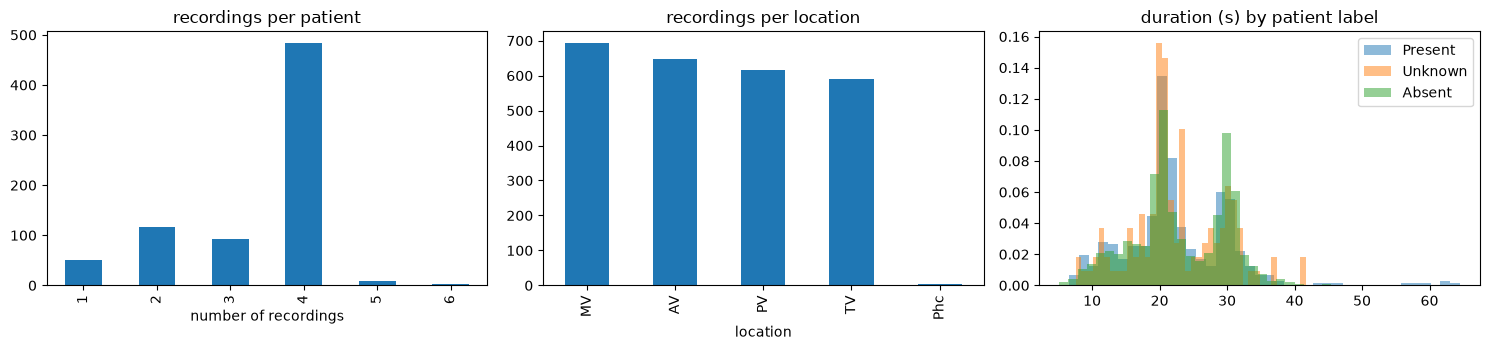

,count,mean,std,min,25%,50%,75%,max
patient_label,,,,,,,,
Absent,1924.0,23.0,7.1,5.2,19.1,21.6,29.6,58.8
Present,497.0,22.5,8.0,6.6,19.2,21.2,28.7,64.5
Unknown,128.0,22.5,6.7,7.6,19.3,21.1,28.0,41.7


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
dev_recs.groupby("patient_id").size().value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("recordings per patient"); axes[0].set_xlabel("number of recordings")
dev_recs["location"].value_counts().plot.bar(ax=axes[1]); axes[1].set_title("recordings per location")
for c in CLASSES:
    axes[2].hist(dev_recs.loc[dev_recs["patient_label"] == c, "duration"], bins=40, alpha=0.5, density=True, label=c)
axes[2].set_title("duration (s) by patient label"); axes[2].legend()
plt.tight_layout(); plt.show()
dev_recs.groupby("patient_label")["duration"].describe().round(1)

Durations are similar across classes, so duration is not a shortcut. Every recording is longer than 5 s, so a fixed
**4 s window** can always be cropped without padding.

### 3.2 Where is the murmur heard?

In [10]:
present = dev_patients[dev_patients["murmur"] == "Present"]
n_heard = present["murmur_locations"].str.split("+").str.len()
n_recorded = present["recording_locations"].str.split("+").str.len()
partial = (present["murmur_locations"].str.split("+").apply(set)
           != present["recording_locations"].str.split("+").apply(set))
print(f"Present patients whose murmur is NOT heard at every recorded location: {partial.sum()} / {len(present)}")
display(pd.crosstab(n_heard.rename("locations where heard"), n_recorded.rename("locations recorded")))
pd.crosstab(dev_recs["patient_label"], dev_recs["rec_label"], margins=True)

Present patients whose murmur is NOT heard at every recorded location: 54 / 143


locations recorded,1,2,3,4,5,6
locations where heard,,,,,,
1,8,6,2,9,0,0
2,0,14,5,18,1,0
3,0,0,8,12,0,1
4,0,0,0,58,0,0
5,0,0,0,0,1,0


rec_label,Absent,Present,Unknown,All
patient_label,,,,
Absent,1924,0,0,1924
Present,93,404,0,497
Unknown,0,0,128,128
All,2017,404,128,2549


For a large share of the *Present* patients, the murmur is not audible at every location. If every recording copied
the patient label, the network would be taught that some recordings without a murmur are *Present*.
→ **Location-aware recording labels** (`src/data.py:recording_label`), shown in the second table: recordings of
*Present* patients made where the murmur was not heard are labelled *Absent*. At the patient level the question
becomes "is the murmur heard at *any* location?", which motivates taking the **maximum** of P(Present) over the
recordings.

In [11]:
for col in ["Systolic murmur timing", "Diastolic murmur timing", "Systolic murmur pitch", "Systolic murmur grading"]:
    print(col, present[col].fillna("none").value_counts().to_dict())

Systolic murmur timing {'Holosystolic': 84, 'Early-systolic': 44, 'Mid-systolic': 14, 'none': 1}
Diastolic murmur timing {'none': 138, 'Early-diastolic': 5}
Systolic murmur pitch {'Low': 68, 'Medium': 39, 'High': 35, 'none': 1}
Systolic murmur grading {'I/VI': 82, 'III/VI': 39, 'II/VI': 21, 'none': 1}


Almost every murmur is **systolic**, so knowing where systole is in the signal helps. Many murmurs are medium or high
pitched, so the input must keep content well above 200 Hz. Grade I/VI (the faintest) is the most frequent grade.

### 3.3 Segmentation files (.tsv): annotation coverage and cardiac cycle

Each .tsv lists intervals labelled 1 = S1, 2 = systole, 3 = S2, 4 = diastole, 0 = not annotated.

,count,mean,std,min,25%,50%,75%,max
patient_label,,,,,,,,
Absent,1924.0,0.45,0.29,-0.0,0.17,0.48,0.70,1.00
Present,497.0,0.41,0.30,0.0,0.11,0.40,0.68,0.96
Unknown,128.0,0.69,0.21,0.0,0.59,0.75,0.84,0.93


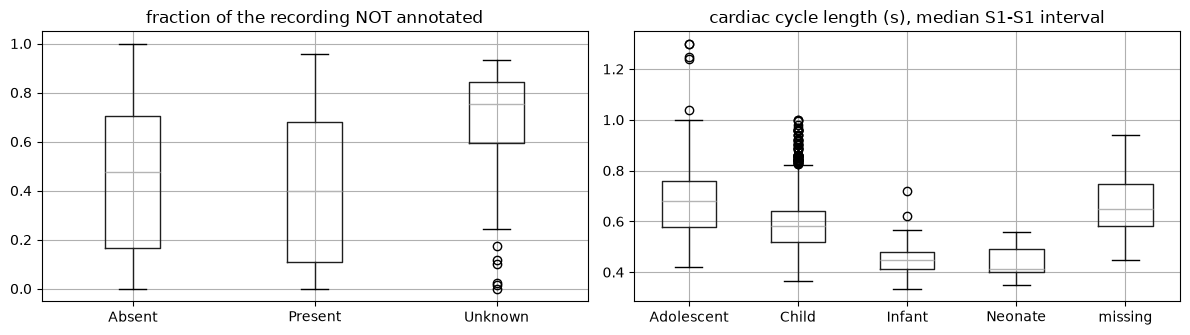

cycle length over all development recordings: median 0.58 s, 95th percentile 0.81 s


In [12]:
dev_recs["unannotated"] = [unannotated_fraction(t, d) for t, d in zip(dev_recs["tsv"], dev_recs["duration"])]

def cycle_length(tsv):
    seg = read_tsv(tsv)
    s1 = seg[seg[:, 2] == 1, 0]
    d = np.diff(s1)
    return np.median(d[(d > 0.2) & (d < 2.0)]) if len(d) else np.nan

dev_recs["cycle_s"] = [cycle_length(t) for t in dev_recs["tsv"]]
display(dev_recs.groupby("patient_label")["unannotated"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
dev_recs.boxplot(column="unannotated", by="patient_label", ax=axes[0])
axes[0].set_title("fraction of the recording NOT annotated"); axes[0].set_xlabel("")
age = dev_recs["patient_id"].map(patients.set_index("patient_id")["age"]).fillna("missing")
dev_recs.assign(age=age).boxplot(column="cycle_s", by="age", ax=axes[1])
axes[1].set_title("cardiac cycle length (s), median S1-S1 interval"); axes[1].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()
print("cycle length over all development recordings: median %.2f s, 95th percentile %.2f s"
      % (dev_recs["cycle_s"].median(), dev_recs["cycle_s"].quantile(0.95)))

- Most of each *Unknown* recording could not be segmented by the annotators: their unannotated fraction is much higher
  than for *Absent* or *Present*. So *Unknown* is largely a **signal-quality** label, and state 0 of the .tsv files is a
  frame-level proxy for it. → In the RNN, an auxiliary head is trained to predict the frame states, state 0 included.
  The .tsv files are training targets only, so they are not needed at inference time.
- Almost every cardiac cycle is shorter than 1 s. A 4 s window therefore contains several beats, and a CNN receptive
  field of about 1 s covers one full cycle.

### 3.4 Looking at the signals

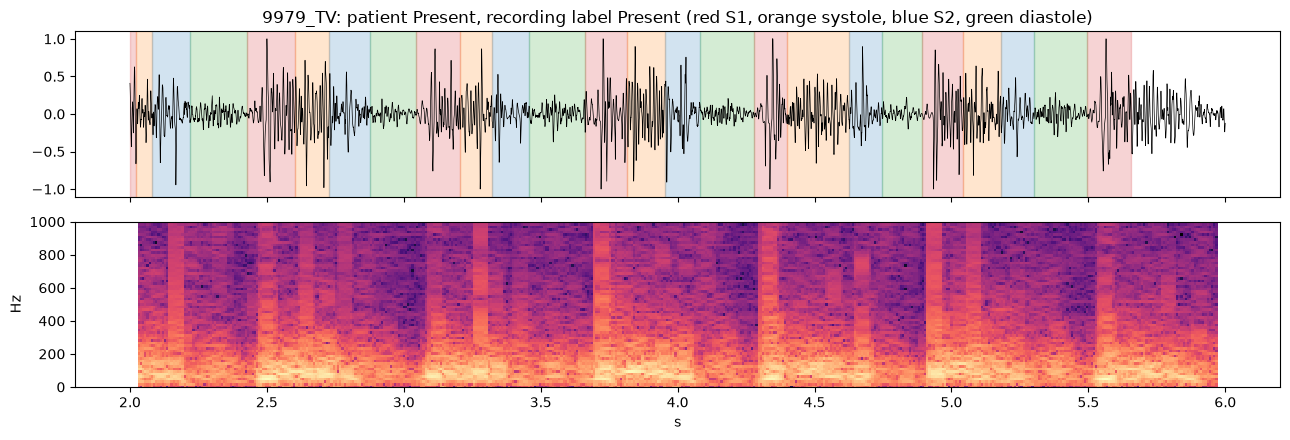

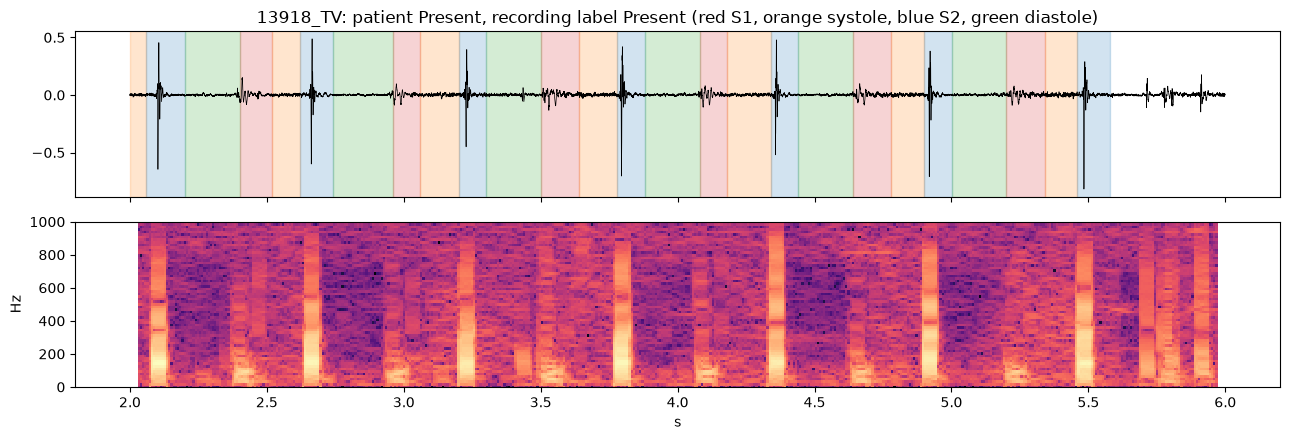

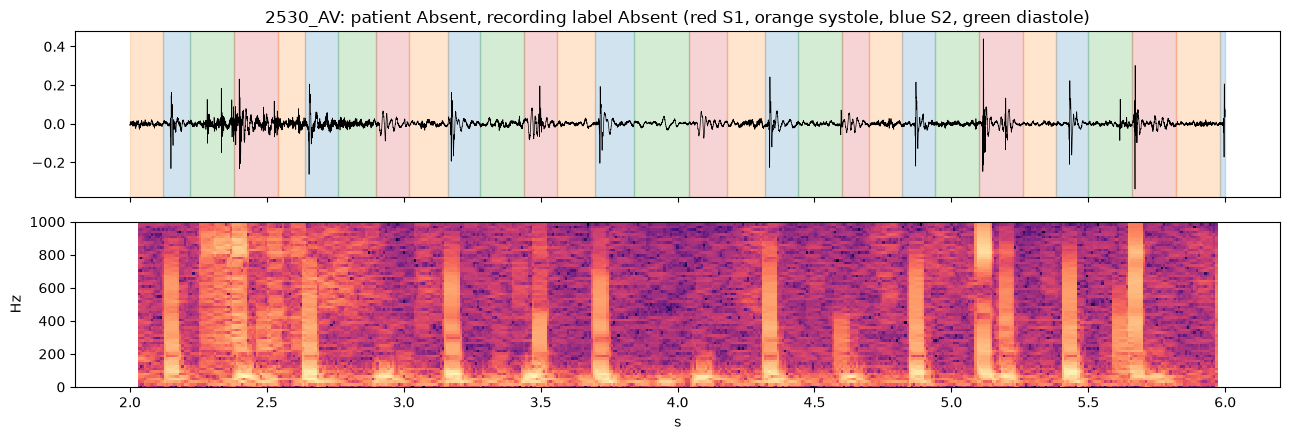

In [13]:
STATE_COLORS = {1: "tab:red", 2: "tab:orange", 3: "tab:blue", 4: "tab:green"}

def show_recording(name, t0=2.0, t1=6.0):
    r = dev_recs.set_index("recording").loc[name]
    x = load_wav(r["wav"])
    t = np.arange(len(x)) / config.SR_RAW
    sel = (t >= t0) & (t < t1)
    fig, axes = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True)
    axes[0].plot(t[sel], x[sel], lw=0.5, color="black")
    for start, end, s in read_tsv(r["tsv"]):
        if s in STATE_COLORS and end > t0 and start < t1:
            axes[0].axvspan(max(start, t0), min(end, t1), color=STATE_COLORS[int(s)], alpha=0.2)
    axes[0].set_title(f"{name}: patient {r['patient_label']}, recording label {r['rec_label']} "
                      "(red S1, orange systole, blue S2, green diastole)")
    f, tt, S = signal.spectrogram(x[sel], fs=config.SR_RAW, nperseg=256, noverlap=224)
    axes[1].pcolormesh(tt + t0, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
    axes[1].set_ylim(0, 1000); axes[1].set_ylabel("Hz"); axes[1].set_xlabel("s")
    plt.tight_layout(); plt.show()

show_recording("9979_TV")     # Present, grade III/VI harsh holosystolic murmur
show_recording("13918_TV")    # Present, grade I/VI murmur heard at TV only
show_recording("2530_AV")     # Absent patient

- **9979_TV** (grade III/VI): every S1 + systole interval (red + orange) is filled with broadband energy.
- **13918_TV** (grade I/VI): the murmur is hardly visible by eye. Many murmurs in this dataset are this faint.
- **2530_AV** (*Absent*): between the heart sounds, systole is quiet.

### 3.5 Spectrum: whole recording vs systole only

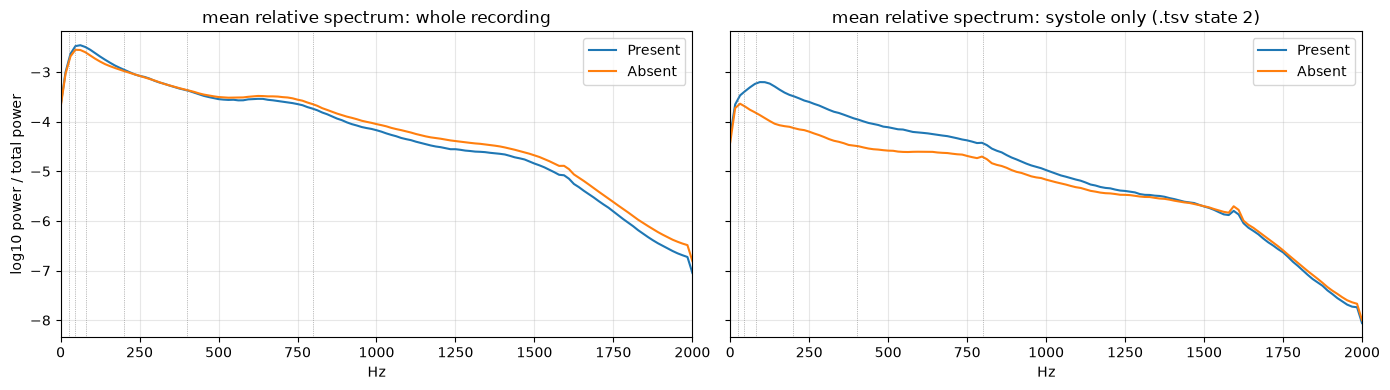

Present minus Absent, in log10 power (+0.30 = twice as much power):


,whole recording,systole only
band (Hz),,
25-100,0.09,0.43
100-200,0.08,0.71
200-400,0.00,0.59
400-800,-0.06,0.40
800-2000,-0.17,0.05


In [14]:
BAND_EDGES = [(25, 100), (100, 200), (200, 400), (400, 800), (800, 2000)]

def spectra_by_label(systole_only):
    out = {c: [] for c in ["Present", "Absent"]}
    for wav, tsv, lab_ in zip(dev_recs["wav"], dev_recs["tsv"], dev_recs["rec_label"]):
        if lab_ == "Unknown":
            continue
        x = load_wav(wav)
        if systole_only:
            parts = [x[int(s * config.SR_RAW):int(e * config.SR_RAW)] for s, e, st in read_tsv(tsv) if st == 2]
            parts = [q - q.mean() for q in parts if len(q) > 64]
            if not parts:
                continue
            p = np.mean([signal.welch(q, fs=config.SR_RAW, nperseg=min(256, len(q)), nfft=256)[1]
                         for q in parts], axis=0)
        else:
            _, p = signal.welch(x, fs=config.SR_RAW, nperseg=256, nfft=256)
        out[lab_].append(np.log10(p / np.mean(x ** 2) + 1e-12))     # relative to the recording's total power
    return {c: np.mean(v, axis=0) for c, v in out.items()}

freqs = np.fft.rfftfreq(256, 1 / config.SR_RAW)
whole, systole = spectra_by_label(False), spectra_by_label(True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (title, sp) in zip(axes, [("whole recording", whole), ("systole only (.tsv state 2)", systole)]):
    for c in sp:
        ax.plot(freqs, sp[c], label=c)
    for lo, hi in config.BANDS:
        ax.axvline(lo, color="gray", lw=0.5, ls=":")
    ax.axvline(config.BANDS[-1][1], color="gray", lw=0.5, ls=":")
    ax.set_xlim(0, 2000); ax.set_xlabel("Hz"); ax.set_title(f"mean relative spectrum: {title}")
    ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("log10 power / total power")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "eda_spectra.png", dpi=120); plt.show()

rows = []
for lo, hi in BAND_EDGES:
    band = (freqs >= lo) & (freqs < hi)
    rows.append({"band (Hz)": f"{lo}-{hi}",
                 "whole recording": np.mean(whole["Present"][band] - whole["Absent"][band]),
                 "systole only": np.mean(systole["Present"][band] - systole["Absent"][band])})
print("Present minus Absent, in log10 power (+0.30 = twice as much power):")
pd.DataFrame(rows).set_index("band (Hz)").round(2)

- Over the **whole recording** the two classes differ little. S1 and S2 dominate the spectrum, and a faint murmur
  disappears in the average.
- Inside **systole**, *Present* recordings have **several times more power** in every band from 25 to 800 Hz, and
  practically the same power above 800 Hz.

→ 2 kHz sampling (Nyquist 1 kHz) and a filter bank covering 25–800 Hz for the CNN; log-mel restricted to 25–800 Hz
for the RNN. → The murmur stands out once the signal is examined **phase by phase**, which is the argument for the
RNN's auxiliary segmentation head.

### 3.6 Summary: from findings to decisions

| Finding | Decision |
|---|---|
| Always-*Present* already beats always-*Absent* on WA | Always-*Present* is the reference line for every result |
| 70 children appear under two Patient IDs | Splits grouped by linked subject (`group_id`) |
| Class proportions differ by campaign | Splits stratified by murmur × campaign |
| Murmur often heard at only some locations | Location-aware recording labels; max of P(Present) over locations |
| Murmurs are almost always systolic, and stand out only phase by phase | Model the cardiac phase (auxiliary segmentation head in the RNN) |
| *Unknown* recordings are mostly not segmentable | Frame state 0 as an auxiliary target (a quality signal) |
| Systolic difference spans 25–800 Hz; cycle < 1 s | 2 kHz, 5-band filter bank 25–800 Hz, 4 s windows, ~1 s receptive field |
| Many murmurs are grade I/VI (faint) | Expect *Present*/*Absent* confusions; plain accuracy is not informative |

## 4. Pre-processing

### 4.1 CNN input: multi-band waveform (`src/preprocessing.py`)

- **4 kHz → 2 kHz** (`scipy.signal.resample_poly`, with anti-aliasing): the useful band ends at ~800 Hz (Section 3.5);
- **filter bank**: 4th-order Butterworth band-pass filters (25–45, 45–80, 80–200, 200–400, 400–800 Hz), applied with
  `sosfiltfilt` (zero phase, so S1/S2 stay aligned across channels). The first four bands are those of Potes et al.
  (winner of the PhysioNet 2016 challenge); we add 400–800 Hz for the medium/high-pitched murmurs;
- **normalization**: robust z-score per channel (median and MAD). Heart sounds are bursty and stethoscope friction
  produces very large spikes, so a plain z-score (mean/std) would depend on how many spikes a recording has. Values
  beyond ±20 are clipped;
- **windows**: during training, one random 4 s crop per recording per epoch. At inference, 4 s windows with 50 %
  overlap, and the window probabilities are averaged per recording.

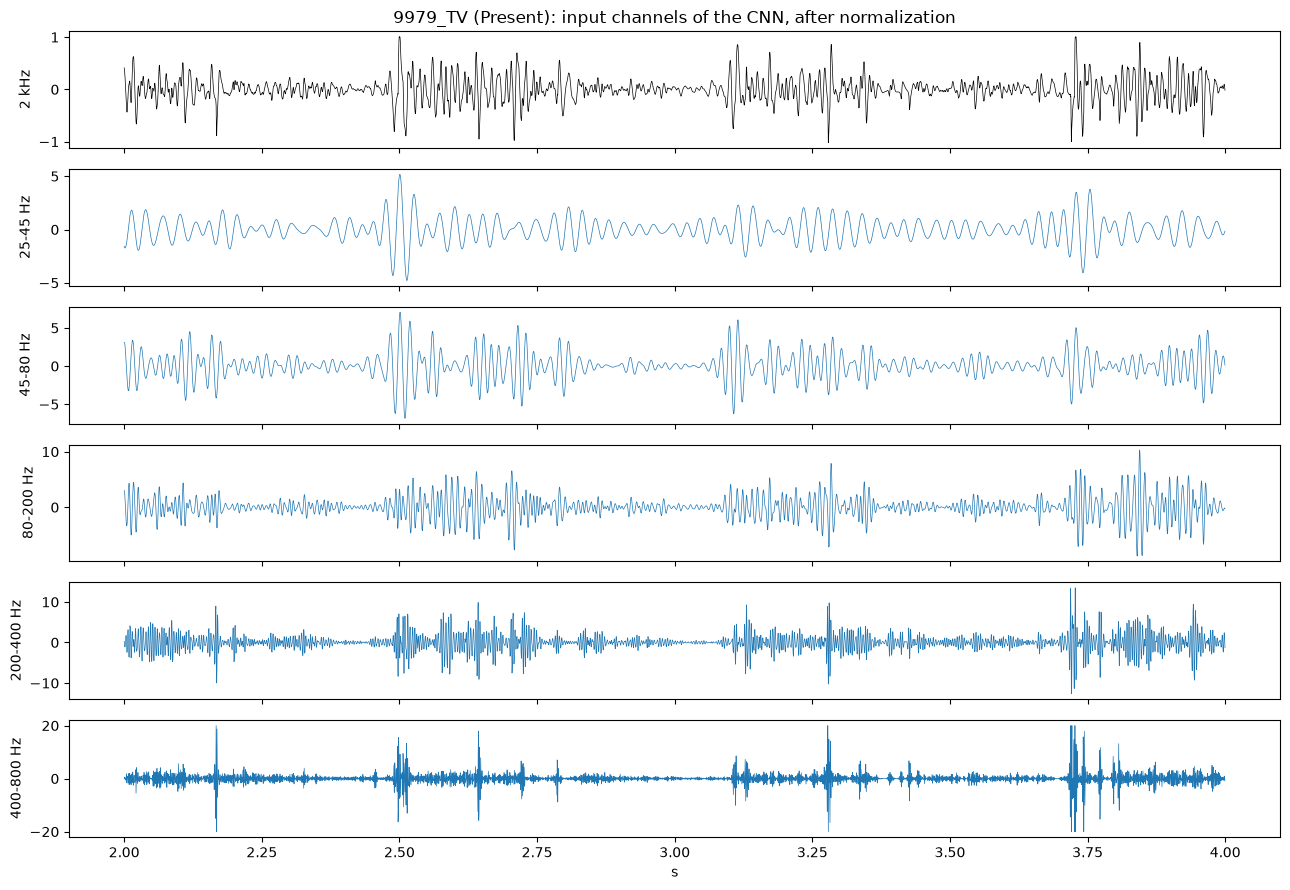

In [15]:
name = "9979_TV"
r = dev_recs.set_index("recording").loc[name]
x2k = downsample(load_wav(r["wav"]))
z = robust_normalize(filterbank(x2k))
t = np.arange(len(x2k)) / config.SR
sel = (t >= 2) & (t < 4)

fig, axes = plt.subplots(len(config.BANDS) + 1, 1, figsize=(13, 9), sharex=True)
axes[0].plot(t[sel], x2k[sel], lw=0.5, color="black"); axes[0].set_ylabel("2 kHz")
for i, (lo, hi) in enumerate(config.BANDS):
    axes[i + 1].plot(t[sel], z[sel, i], lw=0.5)
    axes[i + 1].set_ylabel(f"{lo}-{hi} Hz")
axes[-1].set_xlabel("s"); axes[0].set_title(f"{name} ({r['rec_label']}): input channels of the CNN, after normalization")
plt.tight_layout(); plt.show()

In [16]:
# How much does the clipping remove? (random sample of 300 development recordings)
clipped = []
for path in dev_recs.sample(300, random_state=config.SEED)["wav"]:
    zz = robust_normalize(filterbank(downsample(load_wav(path))))
    clipped.append((np.abs(zz) >= CLIP).mean(axis=0))
print("fraction of clipped samples per band:", {f"{lo}-{hi} Hz": round(float(v), 4)
                                                 for (lo, hi), v in zip(config.BANDS, np.mean(clipped, axis=0))})
w = sliding_windows(z)
print(f"{name}: {len(x2k) / config.SR:.1f} s -> {len(w)} windows of {config.WIN_SECONDS:.0f} s (50 % overlap), shape {w.shape}")

fraction of clipped samples per band: {'25-45 Hz': 0.0005, '45-80 Hz': 0.0027, '80-200 Hz': 0.008, '200-400 Hz': 0.0122, '400-800 Hz': 0.0123}
9979_TV: 22.9 s -> 11 windows of 4 s (50 % overlap), shape (11, 8000, 5)


Clipping touches well under 2 % of the samples, mostly in the upper bands. Those samples are not only friction spikes:
the tallest S1/S2 peaks are flattened too, which shrinks the heart sounds relative to a murmur. This looks harmless,
possibly even helpful, but it has not been tested. **To do:** an ablation with and without clipping.

### 4.2 RNN input: log-mel frames and heart-sound states (`src/features.py`)

- 2 kHz signal → mel spectrogram (window 50 ms, hop 20 ms, 32 mel bands between 25 and 800 Hz) → log → standardized
  per band over time (this removes the stethoscope/patient gain);
- for each frame, the state at its centre according to the .tsv (0 = not annotated, 1 = S1, 2 = systole, 3 = S2,
  4 = diastole). These are the **targets** of the auxiliary head, not inputs of the network;
- 5 s crops (250 frames) for training; 5 s windows with 50 % overlap at inference.

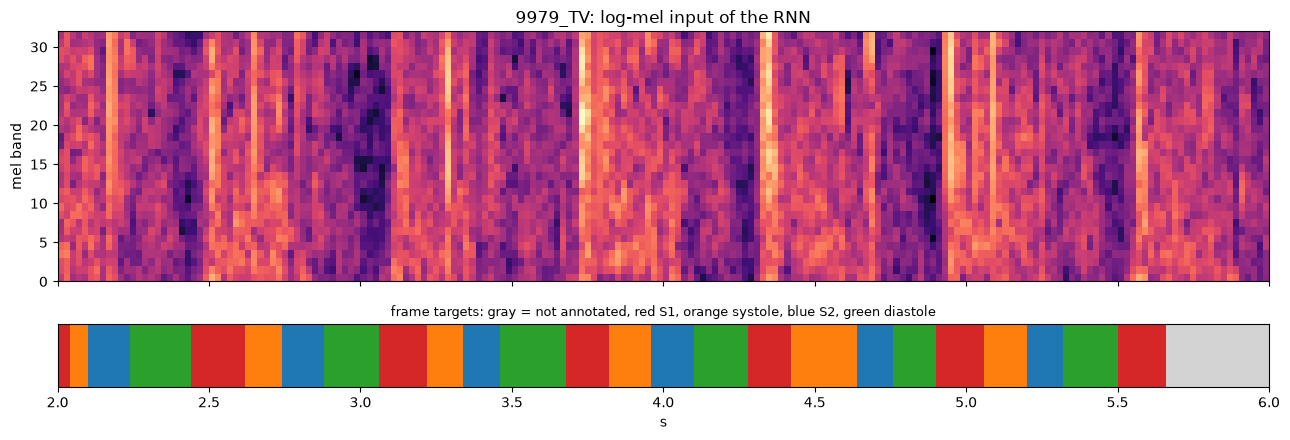

In [17]:
mel = logmel(x2k)
states = frame_labels(r["tsv"], len(mel))
tf_ = np.arange(len(mel)) * config.MEL_HOP_SECONDS
sel = (tf_ >= 2) & (tf_ < 6)
STATE_CMAP = plt.matplotlib.colors.ListedColormap(["lightgray", "tab:red", "tab:orange", "tab:blue", "tab:green"])

fig, axes = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True, gridspec_kw={"height_ratios": [4, 1]})
axes[0].imshow(mel[sel].T, origin="lower", aspect="auto", cmap="magma", extent=[2, 6, 0, config.N_MELS])
axes[0].set_ylabel("mel band"); axes[0].set_title(f"{name}: log-mel input of the RNN")
axes[1].imshow(states[sel][None, :], aspect="auto", cmap=STATE_CMAP, vmin=0, vmax=4, extent=[2, 6, 0, 1])
axes[1].set_yticks([]); axes[1].set_xlabel("s")
axes[1].set_title("frame targets: gray = not annotated, red S1, orange systole, blue S2, green diastole", fontsize=9)
plt.tight_layout(); plt.show()

In [18]:
rnn = load_rnn_inputs(dev_recs)          # cached in cache/rnn/ after the first run
dist = {}
for lab_ in CLASSES:
    s = np.concatenate([rnn[n][1] for n in dev_recs.loc[dev_recs["rec_label"] == lab_, "recording"]])
    dist[lab_] = np.bincount(s, minlength=5) / len(s)
pd.DataFrame(dist, index=config.STATES).T.round(3)

,unannotated,S1,systole,S2,diastole
Present,0.421,0.120,0.125,0.103,0.230
Unknown,0.720,0.057,0.065,0.049,0.109
Absent,0.468,0.108,0.122,0.095,0.207


The frame-level view agrees with Section 3.3: most frames of *Unknown* recordings are in state 0. The auxiliary head
therefore learns two things the murmur head can use: where systole is, and whether the signal can be segmented at all.

## 5. Model 1: 1D CNN

### 5.1 Architecture (`src/models.py:build_cnn1d`)

Input 4 s × 5 bands (8000 × 5). Five blocks of Conv1D (kernel 9, no bias) → BatchNorm → ReLU → MaxPool, with
16 / 32 / 64 / 128 / 128 feature maps and pooling 4 / 4 / 4 / 2 / 2. Then global average pooling (a murmur repeats in
every beat, so we average over time), dropout 0.5, and a softmax with 3 units. The pooling sizes are chosen so that
the receptive field of the last conv layer covers about one cardiac cycle.

In [19]:
build_cnn1d().summary()
rf = receptive_field()
print(f"receptive field of the last conv layer: {rf} samples = {rf / config.SR:.2f} s "
      f"(median cardiac cycle in the development set: {dev_recs['cycle_s'].median():.2f} s)")

Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ waveform (InputLayer)           │ (None, 8000, 5)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 8000, 16)       │           720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8000, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 8000, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2000, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2000, 32)       │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2000, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 2000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 500, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 500, 64)        │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 125, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 125, 128)       │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 125, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 125, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 62, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 62, 128)        │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 62, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 62, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 31, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │             

 Total params: 246,803 (964.07 KB)

 Trainable params: 246,067 (961.20 KB)

 Non-trainable params: 736 (2.88 KB)

receptive field of the last conv layer: 1832 samples = 0.92 s (median cardiac cycle in the development set: 0.58 s)


### 5.2 Training strategy (`src/training.py`)

- **Optimizer**: Adam, learning rate 10⁻³ (the default that worked best in the practical classes), mini-batches of
  32 crops; one epoch = one random crop of every training recording.
- **Augmentation**: random crop position, random gain (×0.8–1.25) and polarity inversion. No time reversal, because
  it would swap S1 and S2.
- **Regularization**: batch normalization, dropout 0.5, augmentation, early stopping.
- **Early stopping on the metric itself**: a callback computes the **patient-level WA** on the validation fold at the
  end of every epoch. Training stops after 10 epochs without improvement (at most 60) and the best weights are
  restored. The validation loss is computed per crop and does not reflect the patient-level decision.
- **Class imbalance**, two configurations compared:

| | loss | patient aggregation | decision rule |
|---|---|---|---|
| **E1** (textbook recipe) | cross-entropy with inverse-frequency class weights | mean over recordings | argmax |
| **E2** (our proposal) | plain cross-entropy | max over recordings for *Present*, mean for the others | Bayes rule for WA: argmax of $w_c\,p_c$, $w=(5,3,1)$ |

**Why the Bayes rule.** WA $=\sum_i w_{y_i}\,[\hat y_i = y_i] \,/\, \sum_i w_{y_i}$. The denominator does not depend on
the predictions, so for each patient the expected gain of predicting class $c$ is $w_c\,p_c$. With calibrated
probabilities, $\arg\max_c w_c p_c$ is the optimal decision. E2 does not reweight the loss on purpose: the costs of
the metric are applied once, at decision time. Applying them in both the loss and the decision would count them twice.

### 5.3 Cross-validation

In [20]:
VARIANTS = {
    "cnn_E1": dict(name="cnn_E1", class_weighted=True,  aggregation="mean",        decision="argmax"),
    "cnn_E2": dict(name="cnn_E2", class_weighted=False, aggregation="max_present", decision="bayes"),
}
OOF, HIST = {}, {}
cnn_arrays = None
for name, variant in VARIANTS.items():
    oof_path = config.RESULTS_DIR / f"{name}_oof.csv"
    hist_path = config.RESULTS_DIR / f"{name}_histories.json"
    if RETRAIN_CNN or not (oof_path.exists() and hist_path.exists()):
        if cnn_arrays is None:
            cnn_arrays = load_cnn_inputs(dev_recs)            # cached in cache/cnn/ after the first run
        oof, hist = run_cv(build_cnn1d, cnn_arrays, dev_recs, splits, variant, win=config.WIN, epochs=60, patience=10)
        oof.to_csv(oof_path, index=False)
        hist_path.write_text(json.dumps({k: {m: [float(v) for v in vals] for m, vals in h.items()}
                                         for k, h in hist.items()}))
    else:
        print(f"{name}: loading saved out-of-fold predictions ({oof_path.name})")
    OOF[name] = pd.read_csv(oof_path)
    HIST[name] = {int(k): h for k, h in json.loads(hist_path.read_text()).items()}

cnn_E1: loading saved out-of-fold predictions (cnn_E1_oof.csv)
cnn_E2: loading saved out-of-fold predictions (cnn_E2_oof.csv)


### 5.4 Learning curves

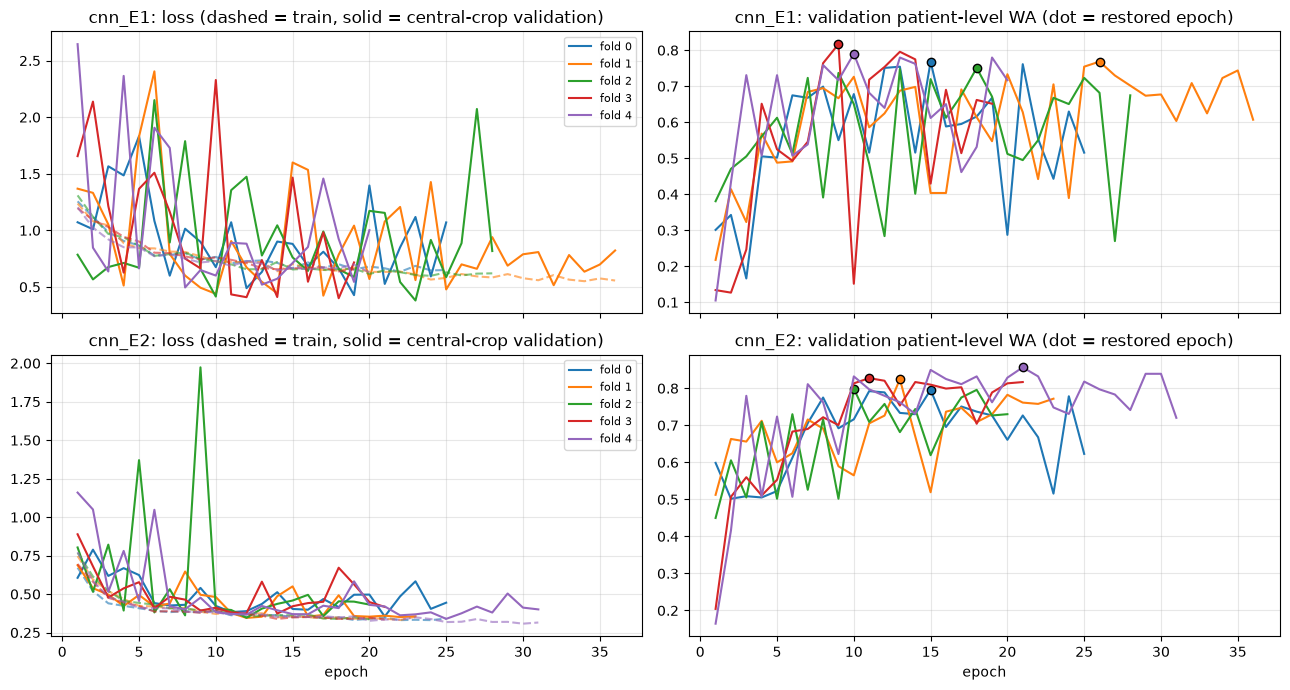

,cnn_E1,cnn_E2
fold 0,best epoch 15 / 25 trained,best epoch 15 / 25 trained
fold 1,best epoch 26 / 36 trained,best epoch 13 / 23 trained
fold 2,best epoch 18 / 28 trained,best epoch 10 / 20 trained
fold 3,best epoch 9 / 19 trained,best epoch 11 / 21 trained
fold 4,best epoch 10 / 20 trained,best epoch 21 / 31 trained


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for row, name in enumerate(VARIANTS):
    for k, h in HIST[name].items():
        ep = np.arange(1, len(h["loss"]) + 1)
        axes[row, 0].plot(ep, h["loss"], "--", color=f"C{k}", alpha=0.6)
        axes[row, 0].plot(ep, h["val_loss"], "-", color=f"C{k}", label=f"fold {k}")
        wa = np.array(h["val_patient_wa"])
        axes[row, 1].plot(ep, wa, "-", color=f"C{k}")
        axes[row, 1].plot(np.argmax(wa) + 1, wa.max(), "o", color=f"C{k}", markeredgecolor="black")
    axes[row, 0].set_title(f"{name}: loss (dashed = train, solid = central-crop validation)")
    axes[row, 1].set_title(f"{name}: validation patient-level WA (dot = restored epoch)")
    axes[row, 0].legend(fontsize=8)
for ax in axes.flat:
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "cnn_learning_curves.png", dpi=120); plt.show()

pd.DataFrame({name: {f"fold {k}": f"best epoch {int(np.argmax(h['val_patient_wa'])) + 1} / {len(h['loss'])} trained"
                     for k, h in HIST[name].items()} for name in VARIANTS})

### 5.5 Patient-level results (out-of-fold, development set)

Each validation patient is predicted by the model of the fold in which it was held out, so every development patient
gets exactly one out-of-fold prediction. We report the WA per fold (mean ± std) and the confusion matrix pooled over
the five folds (rows = predicted, columns = true).

In [22]:
labels = splits.set_index("patient_id")["murmur"]

def evaluate(oof, aggregation, decision):
    per_fold = []
    for k, g in oof.groupby("fold"):
        pp = predict_patients(g, aggregation, decision)
        per_fold.append(weighted_accuracy(labels.loc[pp.index], pp["pred"]))
    return np.array(per_fold), predict_patients(oof, aggregation, decision)

rows, pooled = [], {}
for name, v in VARIANTS.items():
    per_fold, pp = evaluate(OOF[name], v["aggregation"], v["decision"])
    pooled[name] = pp
    rows.append(dict(model=name, **{f"fold {k}": wa for k, wa in enumerate(per_fold)},
                     WA_mean=per_fold.mean(), WA_std=per_fold.std(ddof=1)))
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(config.RESULTS_DIR / "cnn_cv_summary.csv")

print("reference on the same patients: always Present WA = %.3f | always Absent WA = %.3f" % (
      weighted_accuracy(dev_labels, ["Present"] * len(dev_labels)),
      weighted_accuracy(dev_labels, ["Absent"] * len(dev_labels))))
summary.round(3)

reference on the same patients: always Present WA = 0.499 | always Absent WA = 0.388


,fold 0,fold 1,fold 2,fold 3,fold 4,WA_mean,WA_std
model,,,,,,,
cnn_E1,0.768,0.768,0.751,0.817,0.790,0.779,0.025
cnn_E2,0.796,0.825,0.799,0.827,0.857,0.821,0.025


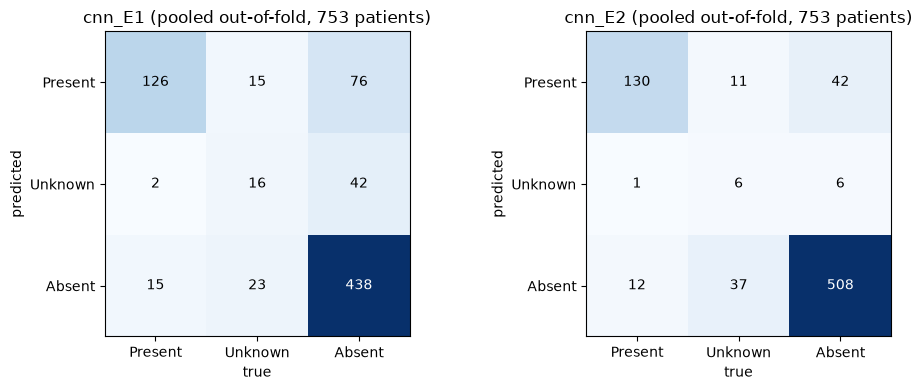

Additional metrics (pooled out-of-fold):


,WA,recall_Present,recall_Unknown,recall_Absent,macro_F1
model,,,,,
cnn_E1,0.779,0.881,0.296,0.788,0.61
cnn_E2,0.821,0.909,0.111,0.914,0.63


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
extra = []
for ax, (name, pp) in zip(axes, pooled.items()):
    plot_confusion(confusion_matrix_pua(labels.loc[pp.index], pp["pred"]),
                   f"{name} (pooled out-of-fold, {len(pp)} patients)", ax)
    extra.append(dict(model=name, **report(labels.loc[pp.index], pp["pred"])))
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "cnn_confusion_matrices.png", dpi=120); plt.show()
print("Additional metrics (pooled out-of-fold):")
pd.DataFrame(extra).set_index("model").round(3)

### 5.6 Which ingredient matters? (post-hoc, no retraining)

The out-of-fold recording probabilities of both trainings can be combined with every aggregation and decision rule.
This separates the effect of the **loss** from the effect of the **decision**. Caveat: each model's early-stopping
epoch was chosen with its own rule, so the other combinations are slightly disadvantaged.

In [24]:
rows = []
for name in VARIANTS:
    for aggregation in ["mean", "max_present"]:
        for decision in ["argmax", "bayes"]:
            per_fold, pp = evaluate(OOF[name], aggregation, decision)
            r_ = report(labels.loc[pp.index], pp["pred"])
            rows.append(dict(training=name, aggregation=aggregation, decision=decision,
                             WA_mean=per_fold.mean(), WA_std=per_fold.std(ddof=1),
                             recall_P=r_["recall_Present"], recall_U=r_["recall_Unknown"], recall_A=r_["recall_Absent"]))
posthoc = pd.DataFrame(rows)
posthoc.to_csv(config.RESULTS_DIR / "cnn_posthoc_rules.csv", index=False)
posthoc.round(3)

,training,aggregation,decision,WA_mean,WA_std,recall_P,recall_U,recall_A
0,cnn_E1,mean,argmax,0.779,0.025,0.881,0.296,0.788
1,cnn_E1,mean,bayes,0.569,0.059,0.993,0.241,0.121
2,cnn_E1,max_present,argmax,0.765,0.027,0.937,0.278,0.685
3,cnn_E1,max_present,bayes,0.543,0.040,0.993,0.222,0.058
4,cnn_E2,mean,argmax,0.667,0.035,0.559,0.000,0.998
5,cnn_E2,mean,bayes,0.776,0.041,0.783,0.111,0.959
6,cnn_E2,max_present,argmax,0.693,0.050,0.615,0.000,0.995
7,cnn_E2,max_present,bayes,0.821,0.025,0.909,0.111,0.914


### 5.7 Recording level: where does the model fail?

Recording-level recall (argmax of the recording probabilities), by recording label and auscultation location.

In [25]:
for name in VARIANTS:
    oof = OOF[name]
    pred = np.array(CLASSES)[oof[[f"p_{c}" for c in CLASSES]].to_numpy().argmax(axis=1)]
    print(name)
    display(oof.assign(correct=pred == oof["rec_label"])
               .groupby(["rec_label", "location"])["correct"].mean().unstack().round(2))

cnn_E1


location,AV,MV,PV,Phc,TV
rec_label,,,,,
Absent,0.64,0.70,0.79,0.5,0.79
Present,0.93,0.94,0.91,1.0,0.91
Unknown,0.46,0.32,0.27,NaN,0.18


cnn_E2


location,AV,MV,PV,Phc,TV
rec_label,,,,,
Absent,0.99,0.99,0.99,1.0,1.00
Present,0.62,0.56,0.68,1.0,0.63
Unknown,0.00,0.00,0.00,NaN,0.00


### 5.8 Interpretation (checkpoint)

**1. Both configurations clearly beat the trivial reference**, and E2 beats E1 in **every** fold: WA 0.821 ± 0.025
against 0.779 ± 0.025 (always-*Present*: 0.499).

**2. The decision rule matters most (table 5.6).** The *same* E2 model scores only 0.693 with argmax: it misses 38 % of
the *Present* patients and never predicts *Unknown*. Applying the Bayes rule raises it to 0.821. Taking the max over
locations instead of the mean adds about +0.045 (0.776 → 0.821), as Section 3.2 suggested.

**3. Applying the costs twice hurts.** The class-weighted model (E1) combined with the Bayes rule drops to 0.54–0.57:
almost every patient is called *Present* (recall of *Absent* 6–12 %). The costs belong either in the loss or in the
decision, not in both.

**4. Class weights make training unstable (5.4).** With inverse-frequency weights an *Unknown* recording weighs ~16×
an *Absent* one. E1's validation curves jump by up to 0.6 WA from one epoch to the next, whereas E2's are much
smoother. A noisy curve also means that early stopping can land on a lucky epoch.

**5. Main weakness: *Unknown*.** In the E2 pooled matrix only 6 of the 54 *Unknown* patients are recognised (37 are
called *Absent*), and at the recording level E2 never chooses *Unknown* by argmax. *Present* is detected well
(130 / 143), and false alarms are 42 of the 556 *Absent* patients.

**6. These numbers are optimistic.** The epoch is chosen on the same validation fold whose WA we report, and the curves
are noisy, so the CV mean is an upper estimate (more so for E1). The unbiased estimate will come from evaluating the
fold ensemble **once** on the locked test set. Values close to the best Challenge entries (≈ 0.78 on their hidden
test set) should not be read as a claim that we match them.

**What we change next:** (a) improve the *Unknown* decision: tune the decision thresholds on the out-of-fold
predictions, and add a signal-quality cue (see the RNN auxiliary head); (b) tune the CNN (window length,
GAP vs GAP+GMP, bands, clipping) with E2 as the base configuration.

## 6. Model 2: multi-task BiGRU (work in progress)

**Status:** inputs, targets and model are implemented, and the full training loop runs end to end. Below is a **short
smoke run on fold 0 only**. It checks that the pipeline works and is *not* a result to compare with the CNN. Full
cross-validation and the ablation of the auxiliary head come next.

### 6.1 Design

| Evidence (Section 3) | Design choice |
|---|---|
| Murmurs are almost always systolic and stand out only inside systole | The network should know **where systole is** → an auxiliary head predicts the heart-sound state of every frame |
| *Unknown* recordings are mostly not segmentable (.tsv state 0) | "Not annotated" is one of the auxiliary classes, so the network learns a frame-level quality signal |
| The murmur is present in only part of the frames | **Attention pooling**: the recording representation is a weighted average of the frames, with learned weights |
| ~2000 training recordings per fold | GRU instead of LSTM (fewer parameters), 64 units per direction, 2 layers |

```
log-mel (T x 32) ─► BiGRU(64) ─► BiGRU(64) ─┬─► Dense(5, softmax) per frame ─────────────► "seg"    (auxiliary, .tsv targets)
                                            └─► attention pooling ─► Dense(32) ─► Dense(3) ─► "murmur"
```

Loss = CE(murmur) + λ · CE(seg), with λ = 0.5 for now. At inference only the "murmur" output is used, so the model also
works on recordings without a segmentation file (the hidden test data may not include one).

### 6.2 Architecture (`src/models.py:build_bigru_mt`)

In [26]:
build_bigru_mt().summary()

Model: "bigru_mt"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ logmel (InputLayer) │ (None, None, 32)  │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, None, 128) │     37,632 │ logmel[0][0]      │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, None, 128) │     74,496 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 1)   │        129 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention (Softmax) │ (None, None, 1)   │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1, 128)    │          0 │ attention[0][0],  │
│                     │                   │            │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 128)       │          0 │ dot[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      4,128 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ murmur (Dense)      │ (None, 3)         │         99 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seg (Dense)         │ (None, None, 5)   │        645 │ bidirectional_1[… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 117,129 (457.54 KB)

 Trainable params: 117,129 (457.54 KB)

 Non-trainable params: 0 (0.00 B)

### 6.3 Smoke run: fold 0, 10 epochs

Same imbalance handling as E2 (plain cross-entropy, max-Present aggregation, Bayes decision), 5 s crops, Adam 10⁻³,
batch 32, early stopping on the validation patient-level WA. No augmentation yet.

In [27]:
RNN_VARIANT = dict(name="rnn_smoke", class_weighted=False, aggregation="max_present", decision="bayes")
rnn_oof_path = config.RESULTS_DIR / "rnn_smoke_oof.csv"
rnn_hist_path = config.RESULTS_DIR / "rnn_smoke_history.json"
rnn_model_path = MODELS_DIR / "rnn_smoke_fold0.keras"
if RETRAIN_RNN or not (rnn_oof_path.exists() and rnn_hist_path.exists() and rnn_model_path.exists()):
    rnn_oof, hist = run_cv(build_bigru_mt, rnn, dev_recs, splits, RNN_VARIANT, win=config.RNN_WIN, folds=[0],
                           epochs=10, patience=10, multitask=True, loss_weights={"murmur": 1.0, "seg": 0.5})
    rnn_oof.to_csv(rnn_oof_path, index=False)
    rnn_hist_path.write_text(json.dumps({m: [float(v) for v in vals] for m, vals in hist[0].items()}))
else:
    print("loading the saved smoke run")
rnn_oof = pd.read_csv(rnn_oof_path)
h = json.loads(rnn_hist_path.read_text())

loading the saved smoke run


best epoch (restored): 6 / 10


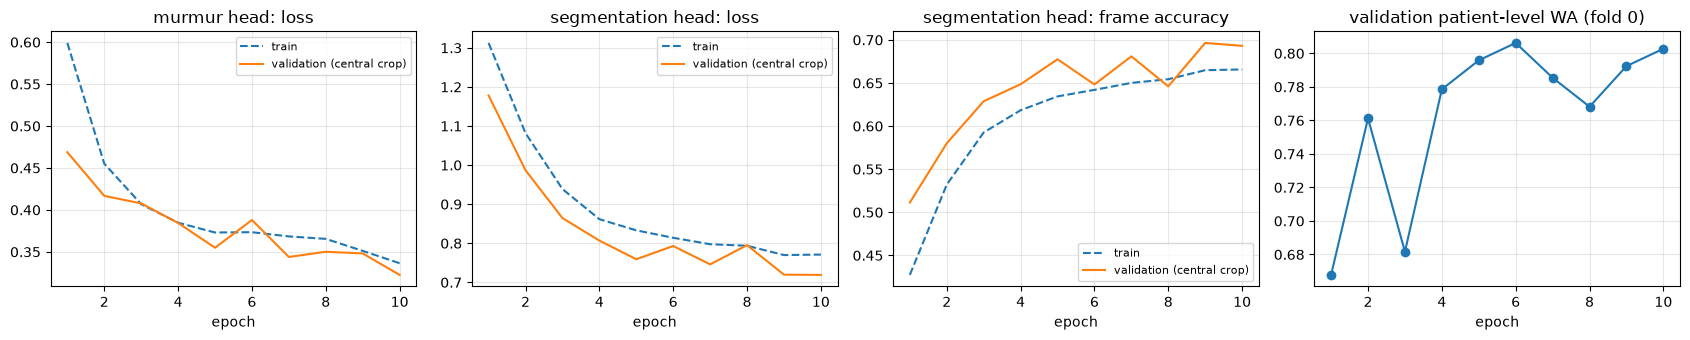

frame accuracy of always predicting the most frequent state: 0.473


In [28]:
ep = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, key, title in [(axes[0], "murmur_loss", "murmur head: loss"), (axes[1], "seg_loss", "segmentation head: loss"),
                       (axes[2], "seg_accuracy", "segmentation head: frame accuracy")]:
    ax.plot(ep, h[key], "--", label="train"); ax.plot(ep, h[f"val_{key}"], "-", label="validation (central crop)")
    ax.set_title(title); ax.legend(fontsize=8)
axes[3].plot(ep, h["val_patient_wa"], "o-"); axes[3].set_title("validation patient-level WA (fold 0)")
print(f"best epoch (restored): {int(np.argmax(h['val_patient_wa'])) + 1} / {len(h['loss'])}")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "rnn_smoke_curves.png", dpi=120); plt.show()

all_states = np.concatenate([rnn[n][1] for n in dev_recs["recording"]])
print(f"frame accuracy of always predicting the most frequent state: {np.bincount(all_states).max() / len(all_states):.3f}")

### 6.4 Does the auxiliary head learn the cardiac cycle?

Predicted vs annotated states for a validation recording (model restored at its best epoch).

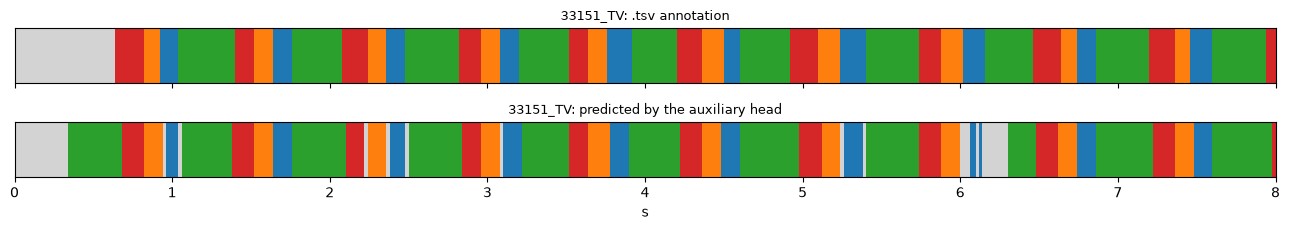

frame agreement on the whole recording: 0.847


In [29]:
rnn_model = keras.models.load_model(rnn_model_path)
_, va = fold_data(dev_recs, splits, 0)
name = va.loc[va["rec_label"] == "Present", "recording"].iloc[0]
x, s = rnn[name]
pred_states = rnn_model.predict(x[None].astype(np.float32), verbose=0)["seg"][0].argmax(axis=-1)

n = min(len(s), 400)
fig, axes = plt.subplots(2, 1, figsize=(13, 2.4), sharex=True)
for ax, st, title in [(axes[0], s, ".tsv annotation"), (axes[1], pred_states, "predicted by the auxiliary head")]:
    ax.imshow(st[None, :n], aspect="auto", cmap=STATE_CMAP, vmin=0, vmax=4, extent=[0, n * config.MEL_HOP_SECONDS, 0, 1])
    ax.set_yticks([]); ax.set_title(f"{name}: {title}", fontsize=9)
axes[1].set_xlabel("s"); plt.tight_layout(); plt.show()
print(f"frame agreement on the whole recording: {(pred_states == s).mean():.3f}")

In [30]:
pp = predict_patients(rnn_oof, RNN_VARIANT["aggregation"], RNN_VARIANT["decision"])
cnn_fold0 = evaluate(OOF["cnn_E2"][OOF["cnn_E2"]["fold"] == 0], "max_present", "bayes")[0][0]
print(f"fold 0 only, 10 epochs, no tuning: RNN patient-level WA = {weighted_accuracy(labels.loc[pp.index], pp['pred']):.3f}"
      f" (CNN E2 on the same fold: {cnn_fold0:.3f})")
confusion_matrix_pua(labels.loc[pp.index], pp["pred"])

fold 0 only, 10 epochs, no tuning: RNN patient-level WA = 0.806 (CNN E2 on the same fold: 0.796)


array([[ 26,   1,   8],
       [  0,   0,   0],
       [  3,  10, 103]])

### 6.5 Interpretation (checkpoint)

- **The auxiliary head learns the cardiac cycle.** Frame accuracy on the validation crops goes from 0.51 to 0.69 in ten
  epochs (always predicting the most frequent state: 0.47) and is still rising. On the example recording the predicted
  S1 → systole → S2 → diastole sequence follows the annotation. The errors are mainly at the boundaries between states
  and in the unannotated parts.
- **The murmur head already works:** fold 0 WA 0.806 after 10 untuned epochs, against 0.796 for the CNN (E2) on the
  same fold. This is a single fold, so it is not a comparison between the models, but the pipeline is sound.
- **Same weakness as the CNN:** no *Unknown* patient of fold 0 is recognised (0 / 11).
- The curves are still improving at epoch 10, so the smoke run is under-trained.

**Next:** full 5-fold CV with more epochs, then the key ablation: **λ = 0 (no auxiliary head) vs λ > 0**. It tells us
whether the segmentation targets actually improve murmur detection, and *Unknown* detection in particular, or only
look good.

## 7. Status and next steps

| Step | 1D CNN | Multi-task BiGRU |
|---|---|---|
| Pre-processing | ✅ | ✅ |
| Architecture | ✅ | ✅ |
| Training strategy | ✅ baseline (E1 vs E2) | 🟡 smoke run only |
| 5-fold CV | ✅ | ⬜ |
| Tuning | ⬜ window length, pooling, bands, clipping | ⬜ λ (incl. λ = 0 ablation), units, augmentation |

Shared next steps:

1. tune the decision thresholds on the out-of-fold predictions (never on the test set);
2. build the ensemble of the five fold models for each architecture;
3. evaluate each final model **once** on the locked test set;
4. write the prediction script for the hidden data (`patient_id,murmur` CSV).